# Attention и Transformers — классификация новостей AG News

Домашнее задание **Модуль 06 (Deep Learning), Тема 07 «Attention и Transformers»**.

### Протокол
1. **Данные:** *AG News Classification Dataset* (Kaggle `amananandrai/ag-news-classification-dataset`: `train.csv` 120 000, `test.csv` 7 600, столбцы `Class Index, Title, Description`). Kaggle API без токена недоступен, поэтому те же файлы берутся из публичной копии оригинального `ag_news_csv` (Zhang et al., 2015); запасной источник — зеркало на Hugging Face (`sh0416/ag_news`, JSONL).
2. **Без утечки:** чистка и удаление дубликатов — **до** сплита; официальный train → стратифицированно **train / val = 108 000 / 12 000** (до удаления дубликатов), официальный **test 7 600** откладывается до самого конца.
3. Словарь, `max_len` и все решения — **только по train / val**. Модель выбирается по validation, test открывается **один раз**.
4. Сначала механизм attention разбирается вручную на игрушечном примере, затем сравниваются baseline (masked mean embeddings, GRU) и Transformer Encoder.

## 1. Окружение
Основное устройство — `mps`. `DataLoader` с `num_workers=0` (данные уже в памяти). Ширина батча округляется вверх до кратного 16: на `mps` каждая новая форма тензора вызывает перекомпиляцию графа.

In [1]:
import html
import json
import math
import re
import time
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset

SEED = 42
NB_START = time.time()

def set_seed(seed=SEED):
    # Воспроизводимость: python/numpy/torch
    import random
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

set_seed()
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
print("torch", torch.__version__, "| mps доступен:", torch.backends.mps.is_available(), "| устройство:", DEVICE)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
CLASSES = ["World", "Sports", "Business", "Sci/Tech"]

torch 2.15.0 | mps доступен: True | устройство: mps


## 2. Данные
`prepare_data()` создаёт `data/train.csv` и `data/test.csv` в формате Kaggle (`Class Index, Title, Description`), только если файлов нет: сначала оригинальные CSV `ag_news_csv` (без заголовка), при недоступности — JSONL-зеркало Hugging Face.

In [2]:
DATA_DIR = Path("data")
COLS = ["Class Index", "Title", "Description"]
PRIMARY = "https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv/{}.csv"
FALLBACK = "https://huggingface.co/datasets/sh0416/ag_news/resolve/main/{}.jsonl"

def _primary(split):
    # Оригинальный CSV Zhang et al.: без заголовка, классы 1..4
    return pd.read_csv(PRIMARY.format(split), header=None, names=COLS)

def _fallback(split):
    # JSONL-зеркало: {"label": 1..4, "title", "description"}
    with urllib.request.urlopen(FALLBACK.format(split), timeout=120) as r:
        rows = [json.loads(line) for line in r.read().decode("utf-8").splitlines() if line.strip()]
    d = pd.DataFrame(rows)
    return d.rename(columns={"label": COLS[0], "title": COLS[1], "description": COLS[2]})[COLS]

def prepare_data():
    DATA_DIR.mkdir(exist_ok=True)
    for split in ["train", "test"]:
        path = DATA_DIR / f"{split}.csv"
        if path.exists():
            continue
        try:
            d = _primary(split); src = "ag_news_csv (Zhang et al.)"
        except Exception as e:
            print(f"основной источник недоступен ({type(e).__name__}), берём зеркало HF"); d = _fallback(split); src = "HF sh0416/ag_news"
        d.to_csv(path, index=False)
        print(f"{path}: {len(d)} строк, источник: {src}")

prepare_data()
train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_raw = pd.read_csv(DATA_DIR / "test.csv")
assert list(train_raw.columns) == COLS and len(train_raw) == 120_000 and len(test_raw) == 7_600
print("train:", train_raw.shape, "| test:", test_raw.shape)
print(train_raw.head(3).to_string(max_colwidth=70))

train: (120000, 3) | test: (7600, 3)
   Class Index                                                Title                                                            Description
0            3    Wall St. Bears Claw Back Into the Black (Reuters)  Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cyn...
1            3  Carlyle Looks Toward Commercial Aerospace (Reuters)  Reuters - Private investment firm Carlyle Group,\which has a reput...
2            3      Oil and Economy Cloud Stocks' Outlook (Reuters)  Reuters - Soaring crude prices plus worries\about the economy and ...


### 2.1. Чистка текста и дубликаты (до сплита)
Текст = `Title + " " + Description`. В исходных данных HTML-сущности часто «потеряли» `&` (`#39;`, `quot;`), есть двойное экранирование (`&amp;lt;b&amp;gt;`) и обратные слэши `\` вместо переносов строк. Восстанавливаем `&`, дважды делаем `html.unescape`, удаляем теги и `\`. Дубликаты ищем по **очищенному** тексту: внутри train оставляем первый экземпляр (группы с конфликтующими метками удаляются целиком), а тексты, совпадающие с test, удаляем из train — иначе модель «видела бы» test.

In [3]:
ENT_FIX = re.compile(r"(?<![&\w])(#\d+|quot|amp|lt|gt|nbsp);")
TAG_RE = re.compile(r"<[^>]+>")

def clean(s: str) -> str:
    s = str(s).replace("\\", " ")
    s = ENT_FIX.sub(r"&\1;", s)                    # '#39;' -> '&#39;', 'quot;' -> '&quot;'
    s = html.unescape(html.unescape(s))            # двойное экранирование &amp;lt;
    s = TAG_RE.sub(" ", s)
    return re.sub(r"\s+", " ", s).strip()

def to_frame(raw):
    d = pd.DataFrame({"text": (raw["Title"].fillna("") + " " + raw["Description"].fillna("")).map(clean),
                      "label": raw["Class Index"].astype(np.int64) - 1})
    return d

n_art = (train_raw["Title"] + " " + train_raw["Description"]).str.contains(r"#\d+;|&\w+;|\\", regex=True).sum()
train_df, test_df = to_frame(train_raw), to_frame(test_raw)
print(f"Строк train с сущностями/слэшами до чистки: {n_art} ({n_art / len(train_raw):.1%})")
print("пример после чистки:", train_df.text.iloc[0])

conflict = train_df.groupby("text")["label"].nunique()
conflict_texts = set(conflict[conflict > 1].index)
n_dup = train_df["text"].duplicated().sum()
train_df = train_df[~train_df.text.isin(conflict_texts)].drop_duplicates("text")
overlap = set(train_df.text) & set(test_df.text)
train_df = train_df[~train_df.text.isin(overlap)].reset_index(drop=True)
print(f"Дубликатов в train: {n_dup}; текстов с конфликтующими метками: {len(conflict_texts)}; "
      f"пересечений с test удалено: {len(overlap)} -> train {len(train_df)}")
print(f"Дубликатов внутри test: {test_df.text.duplicated().sum()} (test не трогаем — официальный)")
print(pd.DataFrame({"train": train_df.label.value_counts(normalize=True).sort_index(),
                    "test": test_df.label.value_counts(normalize=True).sort_index()},
                   ).set_axis(CLASSES).round(4).to_string())

Строк train с сущностями/слэшами до чистки: 45389 (37.8%)
пример после чистки: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling band of ultra-cynics, are seeing green again.


Дубликатов в train: 103; текстов с конфликтующими метками: 27; пересечений с test удалено: 6 -> train 119864
Дубликатов внутри test: 0 (test не трогаем — официальный)
           train  test
World     0.2502  0.25
Sports    0.2502  0.25
Business  0.2499  0.25
Sci/Tech  0.2498  0.25


### 2.2. Токенизация и распределение длин
Токенизатор: lowercase + regex — слова/числа (апостроф внутри слова сохраняется: `don't`, `u.s` разбивается) и отдельные символы `$`, `%` (важны для Business).

count    119864.0
mean         38.4
std          10.2
min           7.0
25%          32.0
50%          38.0
75%          43.0
max         177.0
перцентили: {0.5: 38, 0.9: 49, 0.95: 53, 0.99: 71}
пример: ['wall', 'st', 'bears', 'claw', 'back', 'into', 'the', 'black', 'reuters', 'reuters', 'short', 'sellers', 'wall', "street's", 'dwindling', 'band', 'of', 'ultra', 'cynics', 'are']


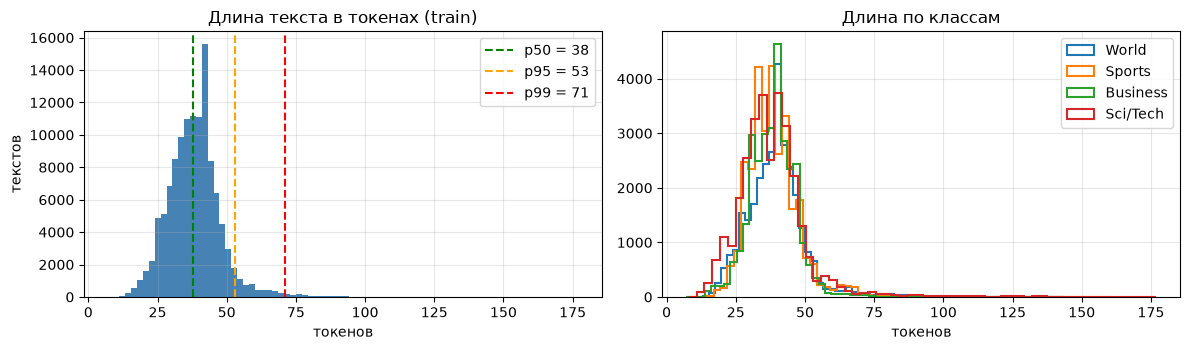

In [4]:
TOKEN_RE = re.compile(r"[a-z0-9]+(?:'[a-z]+)?|[$%]")

def tokenize(s: str):
    return TOKEN_RE.findall(s.lower())

for d in (train_df, test_df):
    d["tokens"] = d["text"].map(tokenize)
    d["n_tok"] = d["tokens"].map(len)
assert train_df.n_tok.min() > 0 and test_df.n_tok.min() > 0
pct = train_df["n_tok"].quantile([0.5, 0.9, 0.95, 0.99]).astype(int)
print(train_df["n_tok"].describe().round(1).to_string())
print("перцентили:", pct.to_dict())
print("пример:", train_df["tokens"].iloc[0][:20])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(train_df["n_tok"], bins=80, color="steelblue")
for q, c in [(0.5, "green"), (0.95, "orange"), (0.99, "red")]:
    ax[0].axvline(pct[q], color=c, ls="--", label=f"p{int(q * 100)} = {pct[q]}")
ax[0].set(title="Длина текста в токенах (train)", xlabel="токенов", ylabel="текстов"); ax[0].legend()
for k, name in enumerate(CLASSES):
    ax[1].hist(train_df.loc[train_df.label == k, "n_tok"], bins=60, histtype="step", lw=1.5, label=name)
ax[1].set(title="Длина по классам", xlabel="токенов"); ax[1].legend()
plt.tight_layout(); plt.show()

### 2.3. Стратифицированный сплит train / val (test уже отложен)

In [5]:
idx_tr, idx_val = train_test_split(train_df.index, test_size=12_000, stratify=train_df["label"], random_state=SEED)
splits = {"train": train_df.loc[idx_tr].reset_index(drop=True),
          "val": train_df.loc[idx_val].reset_index(drop=True),
          "test": test_df.reset_index(drop=True)}
assert not (set(splits["train"].text) & set(splits["val"].text)) and not (set(splits["train"].text) & set(splits["test"].text))
print(pd.DataFrame({k: {"n": len(v), **{c: round((v.label == i).mean(), 4) for i, c in enumerate(CLASSES)}}
                    for k, v in splits.items()}).T.to_string())

              n   World  Sports  Business  Sci/Tech
train  107864.0  0.2502  0.2501    0.2499    0.2498
val     12000.0  0.2502  0.2502    0.2499    0.2498
test     7600.0  0.2500  0.2500    0.2500    0.2500


### 2.4. Словарь только по train
`<pad> = 0`, `<unk> = 1`, `<cls> = 2` (для варианта с CLS-токеном); слово входит в словарь, если встречается в train не менее `min_freq = 3` раз, максимум `MAX_VOCAB = 30 000` элементов. Слова val/test, которых не было в train, становятся `<unk>`.

In [6]:
MIN_FREQ, MAX_VOCAB = 3, 30_000
PAD, UNK, CLS = 0, 1, 2
SPECIALS = ["<pad>", "<unk>", "<cls>"]

counter = Counter(t for toks in splits["train"]["tokens"] for t in toks)
words = [w for w, c in counter.most_common() if c >= MIN_FREQ][: MAX_VOCAB - len(SPECIALS)]
itos = SPECIALS + words
stoi = {w: i for i, w in enumerate(itos)}
VOCAB_SIZE = len(itos)

def unk_rate(part):
    toks = [t for ts in splits[part]["tokens"] for t in ts]
    return sum(t not in stoi for t in toks) / len(toks)

UNK_RATES = {p: unk_rate(p) for p in splits}
print(f"Уникальных токенов в train: {len(counter)}; с частотой >= {MIN_FREQ}: {sum(c >= MIN_FREQ for c in counter.values())}")
print(f"Размер словаря: {VOCAB_SIZE} (частота последнего слова: {counter[itos[-1]]})")
print({p: f"{r:.2%}" for p, r in UNK_RATES.items()}, "<- доля <unk> среди токенов")

Уникальных токенов в train: 64901; с частотой >= 3: 35034
Размер словаря: 30000 (частота последнего слова: 4)
{'train': '1.30%', 'val': '1.68%', 'test': '1.70%'} <- доля <unk> среди токенов


### 2.5. Индексы, `max_len`, padding mask и бакетирование
`MAX_LEN` — p99 длины train, округлённый вверх до кратного 16 (и не больше 96): обрезается ~1 % текстов, а квадратичная по длине стоимость self-attention остаётся малой. Обрезаем хвост (начало новости — заголовок — самое информативное). `collate` дополняет батч `<pad>` справа до ширины, кратной 16, и возвращает **padding mask** `mask = (ids == PAD)` — `True` на PAD, именно так её ждёт `src_key_padding_mask`. Для train — бакетирование по длине (перемешанные куски по `50 × batch` сортируются по длине, затем перемешиваются сами батчи).

In [7]:
MAX_LEN = int(min(96, math.ceil(pct[0.99] / 16) * 16))
BATCH = 128
print("MAX_LEN =", MAX_LEN)

def encode(toks):
    return [stoi.get(t, UNK) for t in toks[:MAX_LEN]]

for name, part in splits.items():
    part["ids"] = part["tokens"].map(encode)
    part["len"] = part["ids"].map(len)
    print(f"{name:5s}: обрезано {(part.n_tok > MAX_LEN).sum():4d} из {len(part)} ({(part.n_tok > MAX_LEN).mean():.2%})")

class NewsDS(Dataset):
    def __init__(self, part):
        self.ids, self.y = part["ids"].tolist(), part["label"].to_numpy()
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return self.ids[i], self.y[i]

def collate(batch):
    # post-padding нулями до ширины, кратной 16 (меньше перекомпиляций на mps); mask: True = PAD
    lengths = torch.tensor([len(x) for x, _ in batch], dtype=torch.long)
    T = min(MAX_LEN, -(-int(lengths.max()) // 16) * 16)
    X = torch.full((len(batch), T), PAD, dtype=torch.long)
    for i, (x, _) in enumerate(batch):
        X[i, : len(x)] = torch.tensor(x)
    y = torch.tensor([t for _, t in batch], dtype=torch.long)
    return X, X.eq(PAD), y

class BucketSampler(torch.utils.data.Sampler):
    # Батчи из текстов близкой длины, порядок батчей случайный
    def __init__(self, lengths, batch, chunk=50, seed=SEED):
        self.lengths, self.batch, self.chunk, self.g = np.asarray(lengths), batch, chunk, np.random.default_rng(seed)
    def __iter__(self):
        idx = self.g.permutation(len(self.lengths)); step = self.batch * self.chunk
        batches = []
        for s in range(0, len(idx), step):
            part = idx[s: s + step]; part = part[np.argsort(self.lengths[part], kind="stable")]
            batches += [part[j: j + self.batch].tolist() for j in range(0, len(part), self.batch)]
        for b in self.g.permutation(len(batches)):
            yield batches[b]
    def __len__(self):
        return math.ceil(len(self.lengths) / self.batch)

EVAL_ORDER = {}

def make_loader(part, train):
    ds = NewsDS(splits[part])
    if train:
        return DataLoader(ds, batch_sampler=BucketSampler(splits[part]["len"], BATCH), collate_fn=collate)
    order = np.argsort(splits[part]["len"].to_numpy(), kind="stable")       # eval: сортировка по длине, без shuffle
    sampler = [order[i: i + 512].tolist() for i in range(0, len(order), 512)]
    EVAL_ORDER[part] = order                                                 # чтобы вернуть предсказания в исходный порядок
    return DataLoader(ds, batch_sampler=sampler, collate_fn=collate)

loaders = {"train": make_loader("train", True), "val": make_loader("val", False), "test": make_loader("test", False)}
Xb, Mb, yb = next(iter(loaders["train"]))
print("батч:", tuple(Xb.shape), "| PAD в батче:", f"{Mb.float().mean():.1%}", "| y:", yb[:8].tolist())

MAX_LEN = 80


train: обрезано  572 из 107864 (0.53%)
val  : обрезано   56 из 12000 (0.47%)
test : обрезано   35 из 7600 (0.46%)
батч: (128, 48) | PAD в батче: 3.2% | y: [3, 2, 3, 1, 2, 2, 0, 1]


### 2.6. Синусоидальный positional encoding
Self-attention сам по себе не знает порядка токенов, поэтому к embedding прибавляется вектор позиции:
$PE_{(pos, 2i)} = \sin(pos / 10000^{2i/d})$, $PE_{(pos, 2i+1)} = \cos(pos / 10000^{2i/d})$. Низкие измерения меняются быстро (различают соседние позиции), высокие — медленно (кодируют грубое положение). Матрица фиксированная (buffer, не обучается).

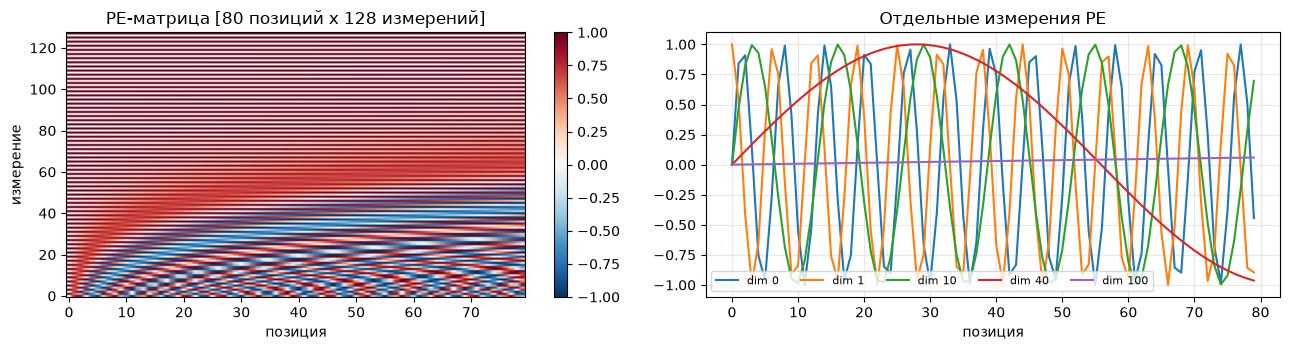

скалярное произведение PE(10)·PE(10+k), k=0,1,5,20: [64.0, 62.1, 47.2, 38.9]


In [8]:
class SinusoidalPE(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pos = torch.arange(max_len).unsqueeze(1)                                   # [L, 1]
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))  # [d/2]
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe, persistent=False)                          # не параметр и не в state_dict
    def forward(self, x):                                                          # x: [B, T, d]
        return x + self.pe[: x.size(1)].unsqueeze(0)

D_MODEL = 128
pe_mat = SinusoidalPE(D_MODEL, MAX_LEN).pe.numpy()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
im = ax[0].imshow(pe_mat.T, aspect="auto", cmap="RdBu_r", origin="lower")
ax[0].set(title=f"PE-матрица [{MAX_LEN} позиций x {D_MODEL} измерений]", xlabel="позиция", ylabel="измерение"); ax[0].grid(False)
plt.colorbar(im, ax=ax[0])
for j in [0, 1, 10, 40, 100]:
    ax[1].plot(pe_mat[:, j], label=f"dim {j}")
ax[1].set(title="Отдельные измерения PE", xlabel="позиция"); ax[1].legend(ncol=5, fontsize=8)
plt.tight_layout(); plt.show()
sim = pe_mat @ pe_mat.T
print("скалярное произведение PE(10)·PE(10+k), k=0,1,5,20:", [round(float(sim[10, 10 + k]), 1) for k in [0, 1, 5, 20]])

## 3. Attention вручную
Игрушечный батч: 2 «предложения» длиной 5 и 3 токена, дополненные до `T = 5`, `d_model = 8`. Случайные матрицы $W_Q, W_K, W_V$ дают запросы, ключи и значения: $Q = XW_Q$, $K = XW_K$, $V = XW_V$;
$\mathrm{Attention}(Q,K,V) = \mathrm{softmax}\left(\frac{QK^\top}{\sqrt{d_k}} + \text{mask}\right)V$.
Padding mask применяется **до softmax**: оценки на PAD-ключах заменяются на $-\infty$, после softmax их вес ровно 0, а веса по разрешённым позициям нормируются в 1.

In [9]:
def scaled_dot_product_attention(q, k, v, mask=None, causal=False, scale=True):
    # q,k,v: [B, T, d]; mask: [B, T] (True = PAD-ключ, исключается)
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1)                                  # [B, Tq, Tk]
    if scale:
        scores = scores / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(mask[:, None, :], float("-inf"))   # до softmax
    if causal:
        T = scores.size(-1)
        scores = scores.masked_fill(torch.triu(torch.ones(T, T, dtype=torch.bool), 1), float("-inf"))
    w = scores.softmax(dim=-1)
    return w @ v, w

torch.manual_seed(SEED)
d, T_toy = 8, 5
toy_tokens = [["stocks", "rise", "on", "oil", "news"], ["team", "wins", "cup"]]
toy_len = torch.tensor([5, 3])
toy_mask = torch.arange(T_toy)[None, :] >= toy_len[:, None]          # [2, 5], True = PAD
X_toy = torch.randn(2, T_toy, d).masked_fill(toy_mask[..., None], 0.0)
W_Q, W_K, W_V = (torch.randn(d, d) / math.sqrt(d) for _ in range(3))
Q, K, V = X_toy @ W_Q, X_toy @ W_K, X_toy @ W_V
out_my, w_my = scaled_dot_product_attention(Q, K, V, toy_mask)

row_sums = w_my.sum(-1)
pad_w = w_my.masked_select(toy_mask[:, None, :].expand_as(w_my))
out_ref = F.scaled_dot_product_attention(Q, K, V, attn_mask=~toy_mask[:, None, :])   # bool: True = разрешено

mha = nn.MultiheadAttention(d, num_heads=1, bias=False, batch_first=True)
with torch.no_grad():                                                # те же W_Q, W_K, W_V; выходная проекция = I
    mha.in_proj_weight.copy_(torch.cat([W_Q.T, W_K.T, W_V.T])); mha.out_proj.weight.copy_(torch.eye(d))
out_mha, w_mha = mha(X_toy, X_toy, X_toy, key_padding_mask=toy_mask, need_weights=True)

print("формы Q, K, V:", tuple(Q.shape), "| веса:", tuple(w_my.shape))
print("суммы весов по строкам:", row_sums.round(decimals=6).tolist())
print("макс. вес на PAD-колонках:", float(pad_w.abs().max()), "(ровно 0)" if float(pad_w.abs().max()) == 0 else "")
print("allclose с F.scaled_dot_product_attention:", torch.allclose(out_my, out_ref, atol=1e-6),
      f"| max|diff| = {(out_my - out_ref).abs().max():.1e}")
print("allclose с nn.MultiheadAttention: выход", torch.allclose(out_my, out_mha, atol=1e-6),
      "| веса", torch.allclose(w_my, w_mha, atol=1e-6))

формы Q, K, V: (2, 5, 8) | веса: (2, 5, 5)
суммы весов по строкам: [[1.0, 1.0, 1.0, 1.0, 1.0], [1.0, 1.0, 1.0, 1.0, 1.0]]
макс. вес на PAD-колонках: 0.0 (ровно 0)
allclose с F.scaled_dot_product_attention: True | max|diff| = 2.4e-07
allclose с nn.MultiheadAttention: выход True | веса True


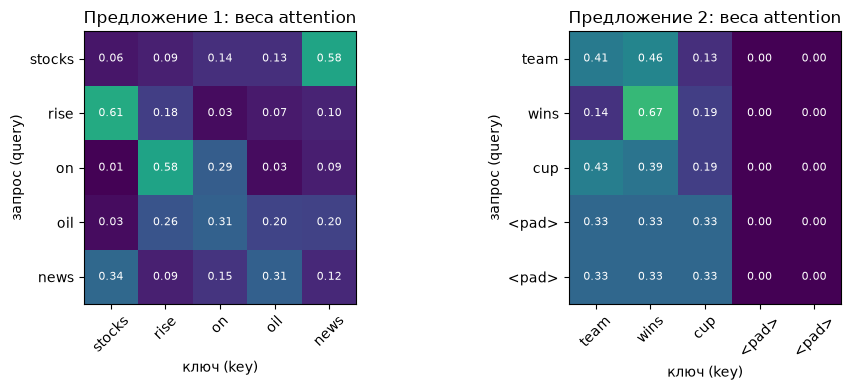

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for b in range(2):
    labels = toy_tokens[b] + ["<pad>"] * (T_toy - len(toy_tokens[b]))
    ax[b].imshow(w_my[b].detach(), cmap="viridis", vmin=0, vmax=1); ax[b].grid(False)
    ax[b].set_xticks(range(T_toy), labels, rotation=45); ax[b].set_yticks(range(T_toy), labels)
    for i in range(T_toy):
        for j in range(T_toy):
            ax[b].text(j, i, f"{w_my[b, i, j]:.2f}", ha="center", va="center", color="w", fontsize=8)
    ax[b].set(title=f"Предложение {b + 1}: веса attention", xlabel="ключ (key)", ylabel="запрос (query)")
plt.tight_layout(); plt.show()

### 3.1. Зачем делить на $\sqrt{d_k}$
Если компоненты $q$ и $k$ независимы с дисперсией 1, то дисперсия $q \cdot k$ равна $d_k$: при большом $d_k$ оценки огромны, softmax вырождается почти в one-hot (энтропия → 0, максимум → 1), а градиенты через softmax почти нулевые. Деление на $\sqrt{d_k}$ возвращает дисперсию к 1.

(равномерное распределение по 16 ключам: энтропия ln16 = 2.773, max = 0.062)
 d_k масштаб  std оценок  энтропия  max веса
   8     нет       2.830     1.300     0.566
   8   ÷√d_k       1.001     2.371     0.240
  64     нет       8.009     0.416     0.843
  64   ÷√d_k       1.001     2.357     0.246
 512     нет      22.671     0.135     0.945
 512   ÷√d_k       1.002     2.356     0.246


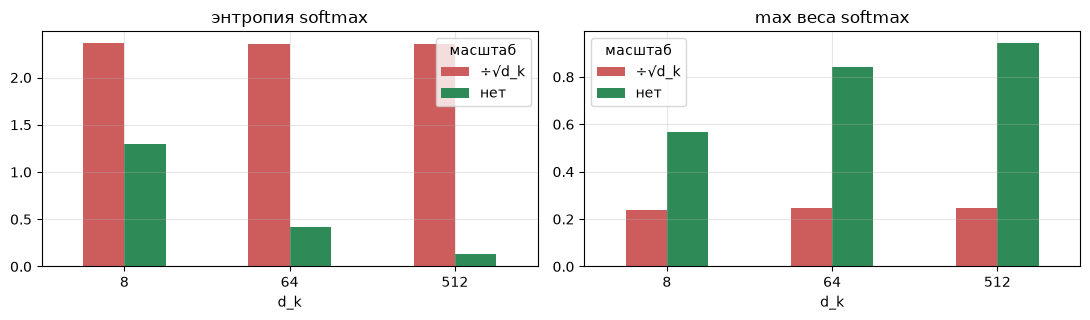

In [11]:
torch.manual_seed(SEED)
rows = []
for d_k in [8, 64, 512]:
    q, k = torch.randn(2000, 1, d_k), torch.randn(2000, 16, d_k)               # 2000 запросов x 16 ключей
    for scale in [False, True]:
        s = (q @ k.transpose(-2, -1)).squeeze(1) / (math.sqrt(d_k) if scale else 1.0)
        p = s.softmax(-1)
        rows.append({"d_k": d_k, "масштаб": "÷√d_k" if scale else "нет", "std оценок": s.std().item(),
                     "энтропия": -(p * p.clamp_min(1e-12).log()).sum(-1).mean().item(), "max веса": p.max(-1).values.mean().item()})
scale_df = pd.DataFrame(rows)
print(f"(равномерное распределение по 16 ключам: энтропия ln16 = {math.log(16):.3f}, max = {1 / 16:.3f})")
print(scale_df.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.3))
for j, col in enumerate(["энтропия", "max веса"]):
    piv = scale_df.pivot(index="d_k", columns="масштаб", values=col)
    piv.plot.bar(ax=ax[j], rot=0, color=["indianred", "seagreen"]); ax[j].set(title=f"{col} softmax", xlabel="d_k")
plt.tight_layout(); plt.show()

### 3.2. Causal mask и permutation equivariance
**Causal mask** (как в декодере) запрещает смотреть на будущие токены: матрица весов нижнетреугольная. **Без PE** self-attention перестановочно эквивариантен: переставили токены на входе — выход переставился точно так же, т.е. модель не различает «dog bites man» и «man bites dog». Добавление PE это ломает.

веса выше диагонали (должны быть 0): 0.0 | суммы строк: [1.0, 1.0, 1.0, 1.0, 1.0]
без PE: f(x[perm]) == f(x)[perm] -> True | веса тоже переставляются: True
с PE:   f(x[perm]) == f(x)[perm] -> False


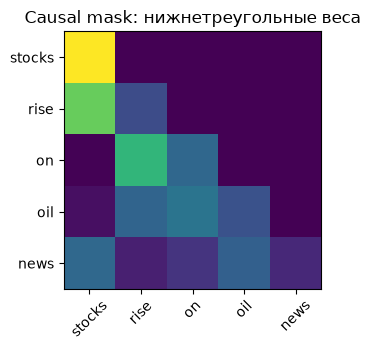

In [12]:
_, w_causal = scaled_dot_product_attention(Q[:1], K[:1], V[:1], causal=True)
print("веса выше диагонали (должны быть 0):", float(torch.triu(w_causal[0], 1).abs().max()),
      "| суммы строк:", w_causal[0].sum(-1).round(decimals=6).tolist())

set_seed()
enc_layer = nn.TransformerEncoderLayer(d_model=d, nhead=2, dim_feedforward=16, dropout=0.0, batch_first=True).eval()
x1 = torch.randn(1, T_toy, d)
perm = torch.tensor([3, 0, 4, 1, 2])
pe_toy = SinusoidalPE(d, T_toy)
with torch.no_grad():
    eq_noPE = torch.allclose(enc_layer(x1)[:, perm], enc_layer(x1[:, perm]), atol=1e-5)
    eq_PE = torch.allclose(enc_layer(pe_toy(x1))[:, perm], enc_layer(pe_toy(x1[:, perm])), atol=1e-5)
    _, w_a = scaled_dot_product_attention(x1, x1, x1); _, w_b = scaled_dot_product_attention(x1[:, perm], x1[:, perm], x1[:, perm])
print("без PE: f(x[perm]) == f(x)[perm] ->", eq_noPE, "| веса тоже переставляются:", torch.allclose(w_a[0][perm][:, perm], w_b[0], atol=1e-6))
print("с PE:   f(x[perm]) == f(x)[perm] ->", eq_PE)

fig, ax = plt.subplots(1, 1, figsize=(4, 3.6))
ax.imshow(w_causal[0].detach(), cmap="viridis", vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(T_toy), toy_tokens[0], rotation=45); ax.set_yticks(range(T_toy), toy_tokens[0])
ax.set(title="Causal mask: нижнетреугольные веса"); plt.tight_layout(); plt.show()

## 4. Модели
Для честного сравнения у всех моделей одинаковые данные, словарь, `MAX_LEN`, `Embedding(VOCAB, 128, padding_idx=0)`, оптимизатор и расписание.

- **MeanEmb** (baseline, как в IMDB) — masked mean embeddings (PAD не участвует) → `Linear(128, 4)`.
- **GRU** (baseline) — однонаправленная GRU 128, состояние после последнего **реального** токена (`gather` по `lengths − 1`).
- **Transformer** — Embedding + синусоидальный PE → dropout → `nn.TransformerEncoder` из 2 слоёв `TransformerEncoderLayer(d_model=128, nhead=4, dim_feedforward=256, dropout=0.1, batch_first=True, norm_first=True)` с `src_key_padding_mask` → pooling → `Linear(128, 4)`. Два варианта pooling: **masked mean** по реальным токенам и **CLS** (в начало добавляется токен `<cls>`, берётся его выход).

**Почему `norm_first=True` (Pre-LN):** LayerNorm стоит перед MHA/FFN внутри residual-ветки, поэтому «прямой» путь residual не нормируется и градиент проходит через стек без затухания — обучение стабильнее и менее чувствительно к lr и warmup, чем у Post-LN из оригинальной статьи. Для Pre-LN нужен финальный `LayerNorm` после энкодера (`norm=` в `nn.TransformerEncoder`). `enable_nested_tensor=False` — nested tensor с `norm_first` всё равно не используется.

In [13]:
class MeanEmb(nn.Module):
    def __init__(self, vocab, d=D_MODEL, n_cls=4):
        super().__init__()
        self.emb = nn.Embedding(vocab, d, padding_idx=PAD); self.fc = nn.Linear(d, n_cls)
    def forward(self, ids, mask):
        keep = (~mask).unsqueeze(-1).float()                                  # [B, T, 1]
        return self.fc((self.emb(ids) * keep).sum(1) / keep.sum(1).clamp_min(1))

class GRUClf(nn.Module):
    def __init__(self, vocab, d=D_MODEL, hidden=128, n_cls=4):
        super().__init__()
        self.emb = nn.Embedding(vocab, d, padding_idx=PAD); self.rnn = nn.GRU(d, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, n_cls)
    def forward(self, ids, mask):
        out, _ = self.rnn(self.emb(ids))                                      # [B, T, H]
        last = (~mask).sum(1) - 1                                             # индекс последнего реального токена
        return self.fc(out[torch.arange(ids.size(0), device=ids.device), last])

class TransformerClf(nn.Module):
    def __init__(self, vocab, d=D_MODEL, nhead=4, ff=256, n_layers=2, dropout=0.1, pooling="mean", n_cls=4):
        super().__init__()
        self.pooling = pooling
        self.emb = nn.Embedding(vocab, d, padding_idx=PAD)
        self.pe = SinusoidalPE(d, MAX_LEN + 1)
        self.drop = nn.Dropout(dropout)
        layer = nn.TransformerEncoderLayer(d, nhead, ff, dropout, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, n_layers, norm=nn.LayerNorm(d), enable_nested_tensor=False)
        self.fc = nn.Linear(d, n_cls)
    def prepare(self, ids, mask):
        # для CLS-варианта добавляем <cls> в начало (он никогда не PAD)
        if self.pooling == "cls":
            ids = torch.cat([torch.full_like(ids[:, :1], CLS), ids], 1)
            mask = torch.cat([torch.zeros_like(mask[:, :1]), mask], 1)
        return ids, mask
    def pool(self, h, mask):
        if self.pooling == "cls":
            return h[:, 0]
        keep = (~mask).unsqueeze(-1).float()
        return (h * keep).sum(1) / keep.sum(1).clamp_min(1)
    def forward(self, ids, mask, use_mask=True):
        ids, mask = self.prepare(ids, mask)
        x = self.drop(self.pe(self.emb(ids)))                                 # [B, T, d]
        h = self.encoder(x, src_key_padding_mask=mask if use_mask else None)   # [B, T, d]
        return self.fc(self.pool(h, mask))                                    # [B, 4]

def n_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

### 4.1. Проверка форм тензоров на одном батче
Прогоняем первые 8 примеров батча через Transformer (mean pooling) по шагам.

In [14]:
set_seed()
m_dbg = TransformerClf(VOCAB_SIZE).eval()
ids8, mask8 = Xb[:8], Mb[:8]
with torch.no_grad():
    emb8 = m_dbg.emb(ids8); embpe8 = m_dbg.pe(emb8)
    h8 = m_dbg.encoder(embpe8, src_key_padding_mask=mask8); pooled8 = m_dbg.pool(h8, mask8); logits8 = m_dbg.fc(pooled8)
    assert torch.allclose(logits8, m_dbg(ids8, mask8), atol=1e-5)
shape_df = pd.DataFrame([("ids", ids8, "индексы токенов, PAD = 0"), ("mask", mask8, "True = PAD (src_key_padding_mask)"),
                         ("emb", emb8, "Embedding"), ("emb + PE", embpe8, "+ позиционное кодирование"),
                         ("encoder out", h8, "2 слоя TransformerEncoderLayer + LayerNorm"),
                         ("pooled", pooled8, "masked mean по реальным токенам"), ("logits", logits8, "Linear(128, 4)")],
                        columns=["тензор", "t", "смысл"])
shape_df["форма"] = shape_df.t.map(lambda t: str(list(t.shape))); shape_df["dtype"] = shape_df.t.map(lambda t: str(t.dtype).replace("torch.", ""))
print(shape_df[["тензор", "форма", "dtype", "смысл"]].to_string(index=False))

     тензор        форма   dtype                                      смысл
        ids      [8, 48]   int64                   индексы токенов, PAD = 0
       mask      [8, 48]    bool          True = PAD (src_key_padding_mask)
        emb [8, 48, 128] float32                                  Embedding
   emb + PE [8, 48, 128] float32                  + позиционное кодирование
encoder out [8, 48, 128] float32 2 слоя TransformerEncoderLayer + LayerNorm
     pooled     [8, 128] float32            masked mean по реальным токенам
     logits       [8, 4] float32                             Linear(128, 4)


### 4.2. Обучение
`AdamW(lr=1e-3, weight_decay=0.01)`, linear warmup 5 % шагов + косинусное затухание, `CrossEntropyLoss`, `clip_grad_norm_(1.0)`, до 6 эпох, Early Stopping по val loss (`patience = 2`) с восстановлением лучших весов. Логируем train/val loss и accuracy, время эпохи (с `torch.mps.synchronize()`).

In [15]:
EPOCHS, LR, WD, PATIENCE = 6, 1e-3, 0.01, 2
criterion = nn.CrossEntropyLoss()

def sync():
    if DEVICE == "mps":
        torch.mps.synchronize()

@torch.no_grad()
def predict(model, part, **kw):
    # вероятности классов в исходном порядке splits[part]
    model.eval(); probs = []
    for X, M, _ in loaders[part]:
        probs.append(model(X.to(DEVICE), M.to(DEVICE), **kw).float().softmax(-1).cpu())
    p = torch.cat(probs).numpy(); out = np.empty_like(p); out[EVAL_ORDER[part]] = p
    return out

def evaluate(model, part):
    p = predict(model, part); y = splits[part]["label"].to_numpy()
    loss = float(F.nll_loss(torch.log(torch.tensor(p).clamp_min(1e-12)), torch.tensor(y)))
    pred = p.argmax(1)
    return {"loss": loss, "acc": accuracy_score(y, pred), "f1": f1_score(y, pred, average="macro")}

def fit(name, model):
    set_seed(); model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WD)
    total = EPOCHS * len(loaders["train"]); warm = int(0.05 * total)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else 0.5 * (1 + math.cos(math.pi * (s - warm) / (total - warm))))
    hist, best, best_state, bad, t0 = [], float("inf"), None, 0, time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); te = time.time(); tl = tc = tn = 0
        for X, M, y in loaders["train"]:
            X, M, y = X.to(DEVICE), M.to(DEVICE), y.to(DEVICE)
            logits = model(X, M); loss = criterion(logits, y)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sched.step()
            tl += loss.item() * len(y); tc += (logits.argmax(1) == y).sum().item(); tn += len(y)
        sync(); ep_time = time.time() - te
        v = evaluate(model, "val")
        hist.append({"epoch": ep, "train_loss": tl / tn, "train_acc": tc / tn, "val_loss": v["loss"], "val_acc": v["acc"], "val_f1": v["f1"], "sec": ep_time})
        print(f"{name:12s} ep {ep}: train loss {tl / tn:.4f} acc {tc / tn:.4f} | val loss {v['loss']:.4f} acc {v['acc']:.4f} f1 {v['f1']:.4f} | {ep_time:.1f} с")
        if v["loss"] < best - 1e-4:
            best, bad = v["loss"], 0; best_state = {k: t.detach().cpu().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"{name}: early stopping на эпохе {ep}"); break
    total_time = time.time() - t0
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), total_time

MODELS = {"MeanEmb": lambda: MeanEmb(VOCAB_SIZE), "GRU": lambda: GRUClf(VOCAB_SIZE),
          "Transformer-mean": lambda: TransformerClf(VOCAB_SIZE, pooling="mean"),
          "Transformer-CLS": lambda: TransformerClf(VOCAB_SIZE, pooling="cls")}
trained, histories, rows = {}, {}, []
for name, ctor in MODELS.items():
    set_seed(); model, hist, tt = fit(name, ctor())
    trained[name], histories[name] = model, hist
    v = evaluate(model, "val")
    rows.append({"Модель": name, "Обучаемых параметров": n_params(model), "Эпох": len(hist), "Время, с": round(tt, 1),
                 "с/эпоху": round(hist.sec.mean(), 1), "Val Loss": round(v["loss"], 4), "Val Acc": round(v["acc"], 4), "Val macro F1": round(v["f1"], 4)})
results = pd.DataFrame(rows)
print(); print(results.to_string(index=False))

MeanEmb      ep 1: train loss 0.8091 acc 0.7133 | val loss 0.3824 acc 0.8831 f1 0.8828 | 7.3 с


MeanEmb      ep 2: train loss 0.3181 acc 0.9002 | val loss 0.3049 acc 0.9048 f1 0.9047 | 7.4 с


MeanEmb      ep 3: train loss 0.2578 acc 0.9179 | val loss 0.2840 acc 0.9101 f1 0.9099 | 7.7 с


MeanEmb      ep 4: train loss 0.2303 acc 0.9266 | val loss 0.2764 acc 0.9128 f1 0.9127 | 8.6 с


MeanEmb      ep 5: train loss 0.2167 acc 0.9312 | val loss 0.2737 acc 0.9132 f1 0.9131 | 12.5 с


MeanEmb      ep 6: train loss 0.2118 acc 0.9331 | val loss 0.2733 acc 0.9132 f1 0.9131 | 7.9 с


... (14 outputs left out)

Transformer-CLS ep 4: train loss 0.2322 acc 0.9205 | val loss 0.2694 acc 0.9133 f1 0.9130 | 19.4 с


Transformer-CLS ep 5: train loss 0.2067 acc 0.9296 | val loss 0.2633 acc 0.9157 f1 0.9156 | 19.3 с


Transformer-CLS ep 6: train loss 0.1949 acc 0.9332 | val loss 0.2634 acc 0.9170 f1 0.9169 | 19.5 с



          Модель  Обучаемых параметров  Эпох  Время, с  с/эпоху  Val Loss  Val Acc  Val macro F1
         MeanEmb               3840516     6      52.5      8.5    0.2733   0.9132        0.9131
             GRU               3939588     5     238.9     47.2    0.2675   0.9095        0.9094
Transformer-mean               4105732     6     113.0     18.4    0.2623   0.9161        0.9159
 Transformer-CLS               4105732     6     119.1     19.4    0.2633   0.9157        0.9156


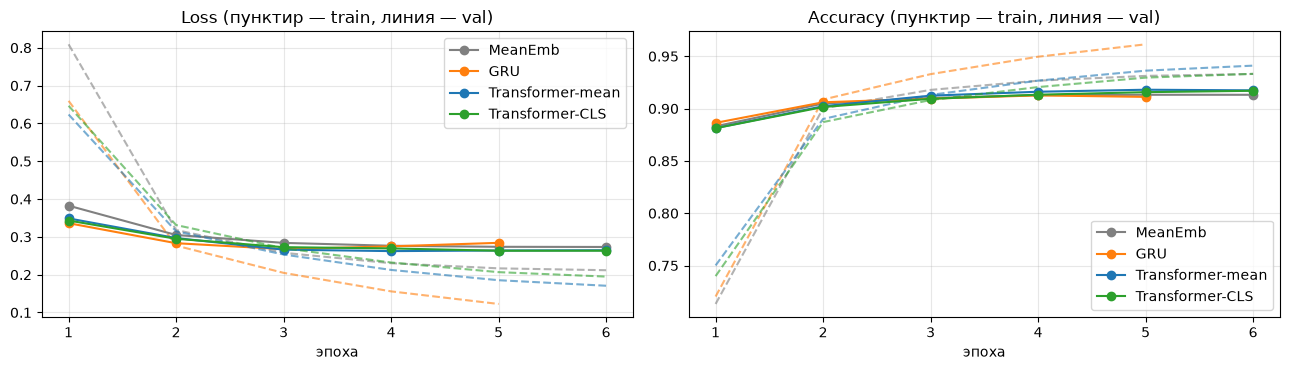

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for (name, h), c in zip(histories.items(), ["gray", "tab:orange", "tab:blue", "tab:green"]):
    ax[0].plot(h.epoch, h.train_loss, "--", color=c, alpha=0.6); ax[0].plot(h.epoch, h.val_loss, "-o", color=c, label=name)
    ax[1].plot(h.epoch, h.train_acc, "--", color=c, alpha=0.6); ax[1].plot(h.epoch, h.val_acc, "-o", color=c, label=name)
ax[0].set(title="Loss (пунктир — train, линия — val)", xlabel="эпоха"); ax[1].set(title="Accuracy (пунктир — train, линия — val)", xlabel="эпоха")
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

## 5. Анализ
### 5.1. Проверка padding mask
(а) Один и тот же короткий пример из val подаётся отдельно (без PAD) и в батче с длинным соседом (дополняется PAD до его длины). С маской logits должны совпасть (до погрешности float32 на `mps`), без маски (`src_key_padding_mask=None`, но pooling по-прежнему только по реальным токенам) — измениться, потому что токены начинают смотреть на PAD.

In [17]:
TF_NAMES = ["Transformer-mean", "Transformer-CLS"]
val_df = splits["val"]
i_short = int(val_df.len.idxmin()); i_long = int(val_df.len.idxmax())
x_s, x_l = torch.tensor(val_df.ids[i_short]), torch.tensor(val_df.ids[i_long])
alone = x_s[None]; pair = torch.full((2, len(x_l)), PAD); pair[0, : len(x_s)] = x_s; pair[1] = x_l
pm_rows = []
with torch.no_grad():
    for name in TF_NAMES:
        m = trained[name].eval()
        for use_mask in [True, False]:
            a = m(alone.to(DEVICE), alone.eq(PAD).to(DEVICE), use_mask=use_mask)[0].cpu()
            b = m(pair.to(DEVICE), pair.eq(PAD).to(DEVICE), use_mask=use_mask)[0].cpu()
            pm_rows.append({"модель": name, "маска": use_mask, "max|Δlogits|": float((a - b).abs().max()),
                            "совпадают (atol 1e-4)": bool(torch.allclose(a, b, atol=1e-4)), "pred один / в паре": f"{int(a.argmax())} / {int(b.argmax())}"})
print(f"короткий пример ({len(x_s)} токенов): {val_df.text[i_short][:90]!r}; длинный сосед: {len(x_l)} токенов")
print(pd.DataFrame(pm_rows).to_string(index=False))

короткий пример (11 токенов): "Dracula's descendant sets Reg straight Letter Transylvania: the spine-tingling truth"; длинный сосед: 80 токенов
          модель  маска  max|Δlogits|  совпадают (atol 1e-4) pred один / в паре
Transformer-mean   True  4.768372e-07                   True              3 / 3
Transformer-mean  False  2.546573e+00                  False              3 / 3
 Transformer-CLS   True  4.172325e-07                   True              2 / 2
 Transformer-CLS  False  2.834683e+00                  False              2 / 3


### 5.2. Веса attention из обученной модели
`nn.TransformerEncoderLayer` вызывает `self_attn(..., need_weights=False)` (и в eval может уйти в fused fast path), поэтому веса наружу не отдаются. Получаем их корректно: повторяем прямой проход по слоям вручную — для Pre-LN вход attention это `norm1(x)`, вызываем `layer.self_attn(h, h, h, key_padding_mask=mask, need_weights=True, average_attn_weights=False)` → `[B, heads, T, T]`, затем сами собираем выход слоя `x + attn`, `x + FFN(norm2(x))`. Корректность проверяем: выход каждого слоя совпадает с `layer(x, src_key_padding_mask=mask)` на реальных позициях, итоговые logits — с `model(ids, mask)`. Примеры берём из **val** (test ещё закрыт).

In [18]:
@torch.no_grad()
def attention_maps(model, ids, mask):
    model.eval(); ids, mask = model.prepare(ids, mask)
    x = model.pe(model.emb(ids)); maps, layer_diff = [], []
    for layer in model.encoder.layers:
        assert layer.norm_first
        h = layer.norm1(x)
        a, w = layer.self_attn(h, h, h, key_padding_mask=mask, need_weights=True, average_attn_weights=False)
        ref = layer(x, src_key_padding_mask=mask)
        x = x + a
        x = x + layer.linear2(layer.activation(layer.linear1(layer.norm2(x))))
        layer_diff.append(float((x - ref)[~mask].abs().max())); maps.append(w)
    logits = model.fc(model.pool(model.encoder.norm(x), mask))
    return maps, logits, layer_diff, mask

best_tf = max(TF_NAMES, key=lambda n: results.set_index("Модель").loc[n, "Val Acc"])
m_att = trained[best_tf]
ex_idx = [int(val_df[val_df.label == k].len.idxmin()) for k in [0, 1, 2, 3]]          # самый короткий пример каждого класса
batch_att = [val_df.ids[i] for i in ex_idx]
Xa = torch.full((len(ex_idx), -(-max(map(len, batch_att)) // 16) * 16), PAD)
for r, ids in enumerate(batch_att):
    Xa[r, : len(ids)] = torch.tensor(ids)
Ma = Xa.eq(PAD)
maps, logits_m, layer_diff, mask_full = attention_maps(m_att, Xa.to(DEVICE), Ma.to(DEVICE))
logits_ref = m_att(Xa.to(DEVICE), Ma.to(DEVICE))
w_pad = maps[-1].masked_select(mask_full[:, None, None, :].expand_as(maps[-1]))
print(f"модель: {best_tf}; форма весов слоя: {tuple(maps[0].shape)} [B, heads, T, T]")
print("max|выход слоя вручную − layer(...)| на реальных позициях:", [f"{d:.1e}" for d in layer_diff])
print(f"max|logits вручную − model(...)| = {(logits_m - logits_ref).abs().max():.1e}")
print("(б) max вес на PAD-ключах:", float(w_pad.abs().max()), "| суммы весов по строкам ∈",
      [round(float(maps[-1].sum(-1).min()), 5), round(float(maps[-1].sum(-1).max()), 5)])

модель: Transformer-mean; форма весов слоя: (4, 4, 16, 16) [B, heads, T, T]
max|выход слоя вручную − layer(...)| на реальных позициях: ['6.3e-07', '1.9e-06']
max|logits вручную − model(...)| = 4.8e-07
(б) max вес на PAD-ключах: 0.0 | суммы весов по строкам ∈ [1.0, 1.0]


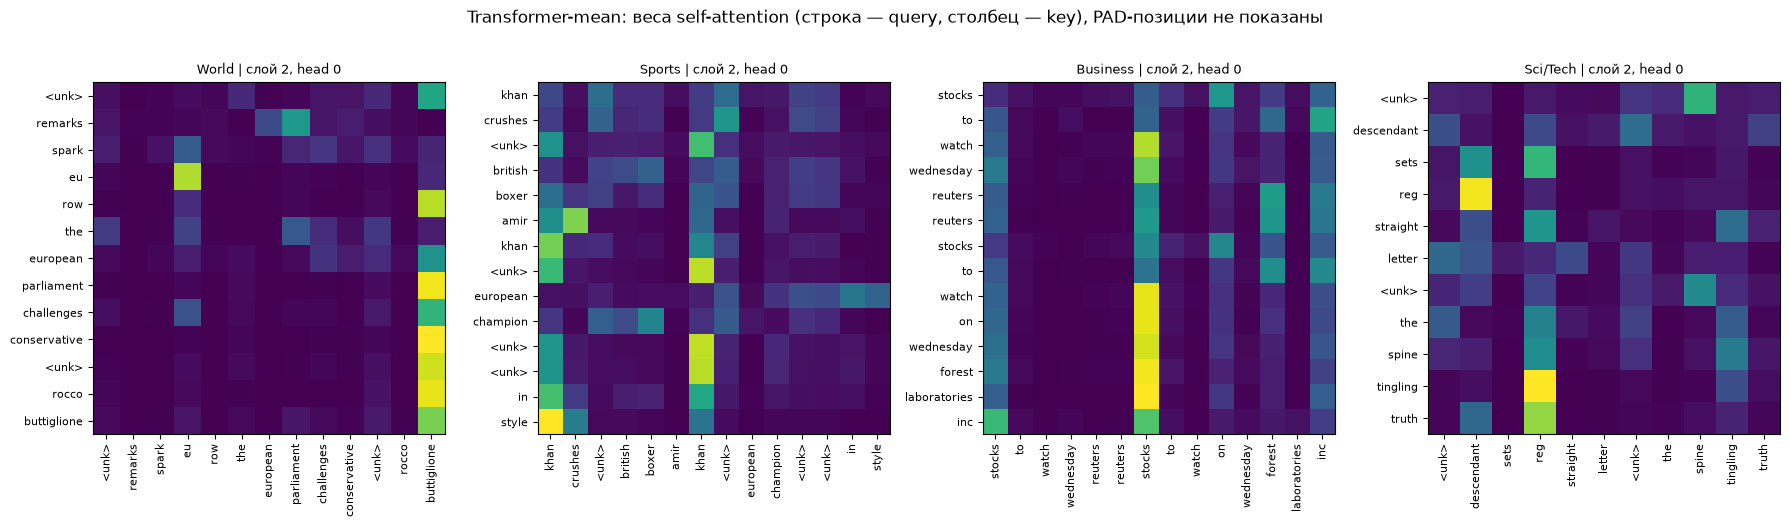

In [19]:
HEAD, LAYER = 0, len(maps) - 1
fig, axes = plt.subplots(1, 4, figsize=(18, 5.2))
for r, ax in enumerate(axes):
    toks = (["<cls>"] if m_att.pooling == "cls" else []) + [itos[t] for t in batch_att[r]]
    n = len(toks); w = maps[LAYER][r, HEAD, :n, :n].cpu()
    ax.imshow(w, cmap="viridis"); ax.grid(False)
    ax.set_xticks(range(n), toks, rotation=90, fontsize=8); ax.set_yticks(range(n), toks, fontsize=8)
    ax.set_title(f"{CLASSES[val_df.label[ex_idx[r]]]} | слой {LAYER + 1}, head {HEAD}", fontsize=9)
plt.suptitle(f"{best_tf}: веса self-attention (строка — query, столбец — key), PAD-позиции не показаны"); plt.tight_layout(); plt.show()

### 5.3. Выбор модели по validation и чекпоинт
Лучшая модель — максимальная **val accuracy**. Сохраняем `state_dict` + конфигурацию + словарь (только тензоры, строки и числа — совместимо с `torch.load(weights_only=True)`), загружаем в **новый** экземпляр и сверяем logits.

In [20]:
best_name = results.loc[results["Val Acc"].idxmax(), "Модель"]
CKPT = Path("checkpoints") / "best_model.pt"; CKPT.parent.mkdir(exist_ok=True)
torch.save({"name": best_name, "state_dict": {k: v.cpu() for k, v in trained[best_name].state_dict().items()},
            "itos": itos, "max_len": MAX_LEN, "classes": CLASSES}, CKPT)
ckpt = torch.load(CKPT, weights_only=True, map_location="cpu")
reloaded = MODELS[ckpt["name"]]().to(DEVICE); reloaded.load_state_dict(ckpt["state_dict"]); reloaded.eval()
Xv, Mv, _ = next(iter(loaders["val"]))
with torch.no_grad():
    diff = (reloaded(Xv.to(DEVICE), Mv.to(DEVICE)) - trained[best_name].eval()(Xv.to(DEVICE), Mv.to(DEVICE))).abs().max().item()
print(f"выбрана по val: {best_name} (val acc {results['Val Acc'].max():.4f}); чекпоинт {CKPT} = {CKPT.stat().st_size / 2**20:.1f} МБ")
print(f"max|Δlogits| исходная vs загруженная: {diff:.1e}; словарь в чекпоинте совпадает: {ckpt['itos'] == itos}")

выбрана по val: Transformer-mean (val acc 0.9161); чекпоинт checkpoints/best_model.pt = 16.2 МБ
max|Δlogits| исходная vs загруженная: 0.0e+00; словарь в чекпоинте совпадает: True


### 5.4. Test — один раз, для выбранной модели
Метрики остальных моделей на test — **только для справки**: выбор уже сделан по validation выше и не меняется.

TEST Transformer-mean: accuracy 0.9132 | macro F1 0.9129
F1 по классам: {'World': np.float64(0.9198), 'Sports': np.float64(0.9665), 'Business': np.float64(0.8802), 'Sci/Tech': np.float64(0.8852)}


          Модель  Обучаемых параметров  Эпох  Время, с  с/эпоху  Val Loss  Val Acc  Val macro F1  Test Acc  Test macro F1 Выбрана по Val
         MeanEmb               3840516     6      52.5      8.5    0.2733   0.9132        0.9131    0.9120         0.9119               
             GRU               3939588     5     238.9     47.2    0.2675   0.9095        0.9094    0.9087         0.9086               
Transformer-mean               4105732     6     113.0     18.4    0.2623   0.9161        0.9159    0.9132         0.9129             да
 Transformer-CLS               4105732     6     119.1     19.4    0.2633   0.9157        0.9156    0.9097         0.9097               


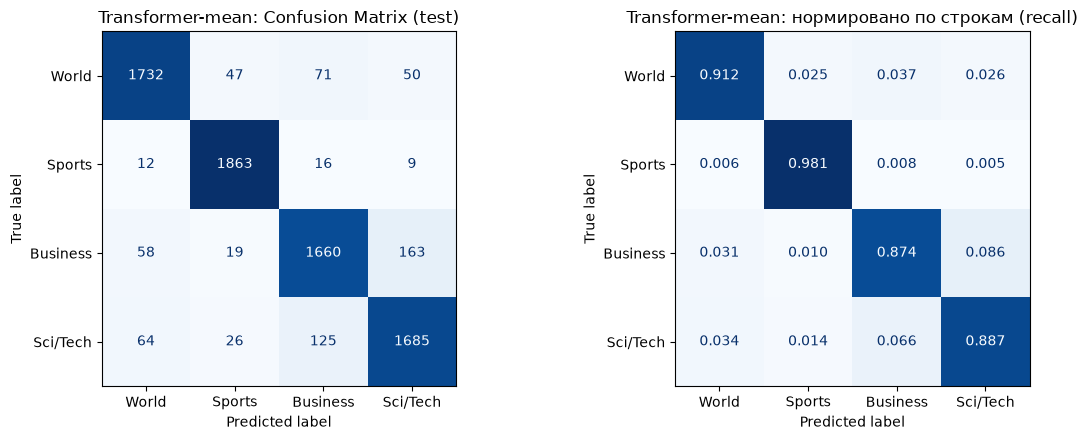

In [21]:
y_test = splits["test"]["label"].to_numpy()
p_test = predict(reloaded, "test"); pred_test = p_test.argmax(1)
TEST_ACC, TEST_F1 = accuracy_score(y_test, pred_test), f1_score(y_test, pred_test, average="macro")
print(f"TEST {best_name}: accuracy {TEST_ACC:.4f} | macro F1 {TEST_F1:.4f}")
print("F1 по классам:", dict(zip(CLASSES, f1_score(y_test, pred_test, average=None).round(4))))

ref = {}
for name, m in trained.items():
    pr = predict(m, "test").argmax(1); ref[name] = (accuracy_score(y_test, pr), f1_score(y_test, pr, average="macro"))
results["Test Acc"] = results["Модель"].map(lambda n: round(ref[n][0], 4))
results["Test macro F1"] = results["Модель"].map(lambda n: round(ref[n][1], 4))
results["Выбрана по Val"] = (results["Модель"] == best_name).map({True: "да", False: ""})
results.to_csv("results_summary.csv", index=False)
print(results.to_string(index=False))

cm = confusion_matrix(y_test, pred_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format="d")
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASSES).plot(ax=ax[1], cmap="Blues", colorbar=False, values_format=".3f")
for a, t in zip(ax, ["Confusion Matrix (test)", "нормировано по строкам (recall)"]):
    a.set_title(f"{best_name}: {t}"); a.grid(False)
plt.tight_layout(); plt.show()

### 5.5. Разбор ошибок на test
10 самых «уверенных» ошибок выбранной модели и самые частые пары «истинный → предсказанный».

In [22]:
pairs = [(f"{CLASSES[i]} → {CLASSES[j]}", int(cm[i, j])) for i in range(4) for j in range(4) if i != j]
print("частые путаницы:", sorted(pairs, key=lambda t: -t[1])[:5])
err = np.where(pred_test != y_test)[0]
err = err[np.argsort(-p_test[err].max(1))][:10]
for k, i in enumerate(err, 1):
    print(f"{k:2d}. истинный {CLASSES[y_test[i]]:8s} | предсказан {CLASSES[pred_test[i]]:8s} (p = {p_test[i].max():.3f})\n    {splits['test'].text[i][:250]}")

частые путаницы: [('Business → Sci/Tech', 163), ('Sci/Tech → Business', 125), ('World → Business', 71), ('Sci/Tech → World', 64), ('Business → World', 58)]
 1. истинный Business | предсказан World    (p = 0.999)
    Indonesian diplomats asked to help improve RI 's bad image JAKARTA (Antara): President Susilo Yudhoyono asked Indonesian diplomats on Monday to help the government improve Indonesia 's bad image.
 2. истинный Sci/Tech | предсказан Sports   (p = 0.999)
    Bryant Makes First Appearance at Trial (AP) AP - NBA star Kobe Bryant arrived at his sexual assault trial Monday as attorneys in the case who spent the weekend poring over questionnaires prepared to question potential jurors individually.
 3. истинный World    | предсказан Sports   (p = 0.999)
    Unknown Nesterenko Makes World Headlines (Reuters) Reuters - Belarus' Yuliya Nesterenko won the top women's athletics gold medal at the Olympics on Saturday, triumphing over a field stripped of many big names because of doping wo

### 5.6. Движение тензора через модель
```
ids [B, T]  (int64, PAD = 0)          mask [B, T]  (True = PAD)
   │ Embedding(V, 128)                     │
   ▼                                       │
x [B, T, 128]  + PE[:T]  → dropout         │
   │                                       │
   ├─ Encoder layer ×2 (Pre-LN) ───────────┤ src_key_padding_mask
   │    h = LayerNorm(x)                   │
   │    x = x + MHA(h, h, h)   4 головы × 32, веса [B, 4, T, T], PAD-ключи = 0
   │    x = x + FFN(LayerNorm(x))   128 → 256 → ReLU → 128
   ▼                                       │
LayerNorm → h [B, T, 128]                  │
   │ pooling: masked mean по ~mask  (или h[:, 0] для <cls>)
   ▼
pooled [B, 128] → Linear(128, 4) → logits [B, 4] → softmax / CrossEntropy
```

In [23]:
print(f"Устройство: {DEVICE}. Общее время выполнения ноутбука: {(time.time() - NB_START) / 60:.1f} мин")

Устройство: mps. Общее время выполнения ноутбука: 8.9 мин


## 6. Выводы
**Данные.** 120 000 + 7 600 новостей, 4 сбалансированных класса. После чистки удалено 103 дубликата, 27 текстов с конфликтующими метками и 6 пересечений с test → train 107 864 / val 12 000 / test 7 600. Словарь 30 000 (только train), доля `<unk>` 1.3 % / 1.7 % / 1.7 %, `MAX_LEN = 80` (p99 = 71, обрезано ~0.5 %).

**Attention вручную.** Своя `scaled_dot_product_attention` совпадает с `F.scaled_dot_product_attention` и `nn.MultiheadAttention` (`allclose`, расхождение ~2e-7); веса на PAD-ключах ровно 0, строки суммируются в 1. Без деления на $\sqrt{d_k}$ при $d_k = 512$ softmax почти one-hot (энтропия 0.14 против 2.36, max 0.95 против 0.25). Без PE перестановка токенов просто переставляет выход — порядок слов модель «не видит».

**Роли компонентов простыми словами.**
- **Q (query)** — «что ищет» токен, **K (key)** — «чем токен может быть полезен», их скалярное произведение даёт, насколько сильно смотреть; **V (value)** — «что токен передаёт», выход — взвешенная сумма V. Несколько голов смотрят на разные типы связей параллельно.
- **Positional encoding** добавляет к embedding информацию о позиции; без него self-attention работает с текстом как с мешком слов.
- **Residual connection** (`x + sublayer(x)`) сохраняет исходный сигнал и даёт градиенту короткий путь через все слои; **LayerNorm** держит масштаб активаций стабильным. В Pre-LN нормализуется только вход подслоя, поэтому обучение с `lr = 1e-3` и коротким warmup прошло без расхождений.

**Сравнение моделей (validation).** Transformer-mean — лучшая val accuracy 0.9161 (macro F1 0.9159, loss 0.2623), CLS-pooling почти так же (0.9157). Baseline MeanEmb отстаёт всего на ~0.3 п.п. (0.9132), но учится в ~2 раза быстрее (8.5 с/эпоху против 18.4 с) при почти том же числе параметров (3.84 M против 4.11 M — у всех моделей 94–100 % параметров приходится на `Embedding` (3.84 M), слои энкодера добавляют всего ~0.26 M). GRU (0.9095) — самая медленная на `mps` (47 с/эпоху, последовательный проход) и быстрее всех переобучается. Почему разрыв мал: тема новости определяется в основном ключевыми словами («stocks», «quarterback», «software»), что уже хорошо ловит мешок слов; контекст и порядок слов, которые даёт Transformer, помогают лишь в части неоднозначных текстов.

**Test (один раз, выбранная по val модель Transformer-mean):** accuracy **0.9132**, macro F1 **0.9129**; хуже всего Business (F1 0.880) и Sci/Tech (0.885), лучше всего Sports (0.967). Главная путаница — **Business ↔ Sci/Tech** (163 + 125 ошибок: новости об IT-компаниях, рынке телекома, отчётах технологических фирм), затем World ↔ Business и Sci/Tech → World. Многие «уверенные» ошибки (p > 0.99) — это, скорее всего, шум разметки самого датасета: спортивные заметки с меткой World, политические новости с меткой Sci/Tech.

**Padding mask и веса attention.** С маской logits примера не зависят от количества PAD (Δ ≈ 5e-7), без маски меняются на 2.5–2.8 и могут менять предсказание. Веса attention получены корректно через ручной вызов `self_attn(..., need_weights=True, average_attn_weights=False)` на `norm1(x)`: выход каждого слоя совпадает с `layer(...)` (~1e-6), веса на PAD = 0. На тепловых картах последнего слоя head 0 стягивает внимание на 1–2 предметных слова (`stocks`, `buttiglione`, `reg`, `khan`).

**Ограничения.** Обучение на `mps` недетерминировано: повторный запуск даёт другие цифры (в пределах ~0.1–0.3 п.п.), поэтому разница 0.04 п.п. между Transformer-mean и CLS статистически незначима. Всё обучение — на полном train, весь ноутбук выполняется ~9 мин.